# Crop Recommendation with a Feed-Forward Neural Network (FNN)

**Module:** ITLPA701 Python and Fundamentals of AI  |  **CAT 2 Practical**  |  **Approach:** Deep learning (FNN, Keras/TensorFlow)

## Project summary
This project builds a crop recommendation system that predicts the most suitable crop for a farmer based on soil and weather conditions. The model uses seven input features: nitrogen, phosphorus, potassium, temperature, humidity, soil pH, and rainfall.

The task is a multi-class classification problem with 22 crop categories. The system follows a standard machine-learning pipeline:

1. load and inspect the data
2. clean and prepare the dataset
3. engineer agronomic features
4. train and compare multiple FNN models
5. select the best model using validation performance
6. evaluate on unseen test data
7. save the trained model and deploy it through a Gradio app

## Problem statement
A farmer records soil nutrients and climate conditions and wants to know which crop is most likely to grow well in those conditions. The model predicts the best crop and provides a ranked list of the top three possible choices.

## Application functionality
- load and validate the Kaggle Crop Recommendation dataset
- preprocess the data and create a fair train/validation/test split
- engineer extra agronomic features for better model understanding
- train and compare three FNN experiments
- evaluate using accuracy, precision, recall, F1-score, and confusion matrix
- save the trained model and deploy it in a Gradio web app

## Model architecture
`7 inputs -> feature engineering -> StandardScaler -> Dense layers (ReLU + Dropout) -> Softmax(22) -> top-3 crops`


## 1. Environment setup

This section confirms the project environment is ready and checks the installed versions of the main libraries. We also verify that the configuration file is present before training starts.


In [16]:
import os, sys, json
import numpy as np, pandas as pd
import tensorflow as tf
import sklearn, matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# make sure we run from the project folder (where config.json lives)
if not os.path.exists("config.json") and os.path.exists("../config.json"):
    os.chdir("..")

print("Python    :", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)
cfg = json.load(open("config.json"))
print("Seed:", cfg["seed"], "| data file:", cfg["data_path"])

Python    : 3.14.7
TensorFlow: 2.22.0-rc0
scikit-learn: 1.9.0 | pandas: 3.0.5
Seed: 42 | data file: data/Crop_recommendation.csv


## 2. Data acquisition
Source: Kaggle - *Crop Recommendation Dataset* (Atharva Ingle). The CSV must be saved as `data/Crop_recommendation.csv`.

In [2]:
from src.data_prep import load_data, quality_report, clean_data, encode_labels, split_indices, scale_features
df = load_data(cfg["data_path"])
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


## 3. Data pre-processing

In [4]:
report = quality_report(df)
print(json.dumps(report, indent=2))

{
  "rows": 2200,
  "columns": [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall",
    "label"
  ],
  "missing_values": 0,
  "duplicate_rows": 0,
  "n_classes": 22,
  "rows_per_class_min": 100,
  "rows_per_class_max": 100,
  "iqr_outliers_per_feature": {
    "N": 0,
    "P": 138,
    "K": 200,
    "temperature": 86,
    "humidity": 30,
    "ph": 57,
    "rainfall": 100
  }
}


**What the checks tell us.** Missing values, duplicates and IQR outliers are counted *before* any change is made. Duplicates and missing rows are removed; outliers are **kept** because extreme but real soil/weather readings (for example very high rainfall for rice) are valid information for the model.

Rows removed by cleaning: 0 | rows left: 2200


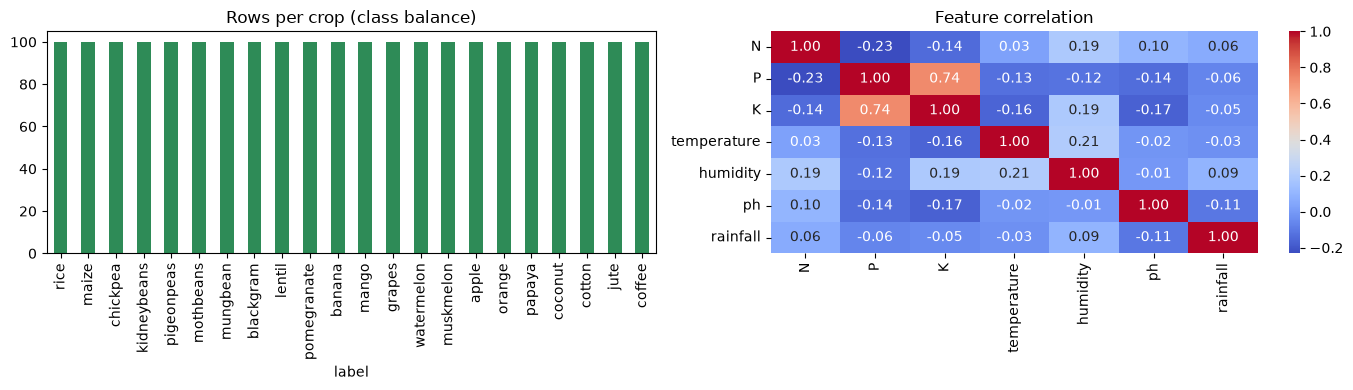

In [5]:
df, removed = clean_data(df)
print("Rows removed by cleaning:", removed, "| rows left:", len(df))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["label"].value_counts().plot(kind="bar", ax=axes[0], color="seagreen")
axes[0].set_title("Rows per crop (class balance)")
sns.heatmap(df.drop(columns="label").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

In [6]:
y, encoder = encode_labels(df)                     # crop name -> integer 0..21
class_names = list(encoder.classes_)
train_idx, val_idx, test_idx = split_indices(y, cfg["test_size"], cfg["val_size"], cfg["seed"])
print(f"train={len(train_idx)}  validation={len(val_idx)}  test={len(test_idx)}  classes={len(class_names)}")

train=1540  validation=330  test=330  classes=22


**Why these steps?**
- **Label encoding** - a neural network needs numbers, not crop names.
- **Stratified 70/15/15 split** - every crop appears in train, validation and test in the same proportion. The validation set is used to *choose* the model; the test set is touched **once**, at the end.
- **Standard scaling (fit on training data only)** - N, P, K are 0-140+, pH is 3-10 and rainfall is up to ~300 mm. Without scaling, large-valued features dominate training. Fitting the scaler on training data only prevents data leakage.

## 4. Feature engineering

In [7]:
from src.features import add_engineered_features, ENGINEERED_FEATURES
fe = add_engineered_features(df.drop(columns="label"))
print("New features:", ENGINEERED_FEATURES)
fe[ENGINEERED_FEATURES].head()

New features: ['npk_total', 'n_to_p', 'n_to_k', 'p_to_k', 'temp_humidity_index', 'ph_deviation']


,npk_total,n_to_p,n_to_k,p_to_k,temp_humidity_index,ph_deviation
0,175,2.093023,2.045455,0.954545,17.121963,0.002985
1,184,1.440678,2.023810,1.380952,17.485957,0.538096
2,159,1.071429,1.333333,1.222222,18.937446,1.340207
3,149,2.055556,1.804878,0.853659,21.234829,0.480401
4,162,1.813953,1.813953,0.976744,16.427204,1.128473


| Feature | Meaning |
|---|---|
| `npk_total` | overall soil fertility (N + P + K) |
| `n_to_p`, `n_to_k`, `p_to_k` | nutrient *balance*; crops care about ratios, not only amounts |
| `temp_humidity_index` | warm-and-humid vs cool-and-dry climate in one number |
| `ph_deviation` | distance from neutral pH 6.5 (acid- vs alkaline-loving crops) |

Experiment **v3** uses these on top of the 7 raw features, so we can measure whether they really help.

## 5. Choice of approach and model parameters

**Why an FNN?** The data is a small *tabular* table (7 numeric inputs, 2,200 rows). A feed-forward network is the standard deep-learning model for tabular data; CNNs suit images and RNNs suit sequences, so neither fits here.

| Parameter | Value(s) tried | Reason |
|---|---|---|
| Hidden layers / units | [32] -> [64,32] -> [128,64,32] | more capacity lets the network learn interactions between nutrients and climate |
| Activation | ReLU (hidden), Softmax (output) | ReLU trains fast; softmax gives one probability per crop (sums to 1) |
| Dropout | 0 -> 0.2 -> 0.3 | randomly switches off neurons to reduce over-fitting |
| Optimizer / learning rate | Adam, 0.01 -> 0.001 | Adam adapts step sizes; a smaller rate gives steadier training |
| Loss | sparse categorical cross-entropy | multi-class problem with integer labels |
| Batch size | 32 | small batches suit a small dataset |
| Epochs + early stopping | up to 150, patience 15 | training stops when validation loss stops improving and the best weights are restored |

## 6. Implementation: train and compare the experiments

In [8]:
import train
meta, exp_df = train.run(verbose=0)       # trains v1, v2, v3, evaluates, saves model
exp_df

Data quality: {
  "rows": 2200,
  "columns": [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall",
    "label"
  ],
  "missing_values": 0,
  "duplicate_rows": 0,
  "n_classes": 22,
  "rows_per_class_min": 100,
  "rows_per_class_max": 100,
  "iqr_outliers_per_feature": {
    "N": 0,
    "P": 138,
    "K": 200,
    "temperature": 86,
    "humidity": 30,
    "ph": 57,
    "rainfall": 100
  },
  "rows_removed_by_cleaning": 0
}
Split -> train 1540, val 330, test 330
{'experiment': 'v1_baseline', 'features': 7, 'hidden_units': '[32]', 'dropout': 0.0, 'learning_rate': 0.01, 'epochs_run': 92, 'train_accuracy': 0.9955, 'val_accuracy': 0.9909, 'val_f1_macro': 0.9909, 'val_loss': 0.0176, 'train_seconds': 16.6}
{'experiment': 'v2_deeper_regularised', 'features': 7, 'hidden_units': '[64, 32]', 'dropout': 0.2, 'learning_rate': 0.001, 'epochs_run': 150, 'train_accuracy': 0.9883, 'val_accuracy': 0.9909, 'val_f1_macro': 0.991, 'val_loss': 0.0322, 'train_seconds': 25.

,experiment,features,hidden_units,dropout,learning_rate,epochs_run,train_accuracy,val_accuracy,val_f1_macro,val_loss,train_seconds
0,v1_baseline,7,[32],0.0,0.010,92,0.9955,0.9909,0.9909,0.0176,16.6
1,v2_deeper_regularised,7,"[64, 32]",0.2,0.001,150,0.9883,0.9909,0.9910,0.0322,25.3
2,v3_engineered_features,13,"[128, 64, 32]",0.3,0.001,94,0.9877,0.9939,0.9939,0.0294,17.3


**Adjusting from the evaluation results.** v1 is a simple baseline. We then tested two changes: more capacity with dropout (v2), and engineered features with a deeper network (v3). All three are compared on the **validation set** (never the test set); the best is selected automatically, with ties broken by F1 and then lower validation loss. The next cell interprets the comparison for *your* run.

In [9]:
n_val = len(val_idx)
tbl = exp_df.sort_values(["val_accuracy", "val_f1_macro", "val_loss"], ascending=[False, False, True]).reset_index(drop=True)
winner = tbl.iloc[0]
print(f"Selected model: {winner['experiment']}  (validation accuracy {winner['val_accuracy']:.4f}, {n_val} validation samples)")
for _, r in tbl.iloc[1:].iterrows():
    miss = round((winner["val_accuracy"] - r["val_accuracy"]) * n_val)
    print(f"  - {r['experiment']}: {miss} more validation sample(s) wrong than the selected model")
spread = round((tbl["val_accuracy"].max() - tbl["val_accuracy"].min()) * n_val)
if spread <= 3:
    print(f"\nAll experiments are within {spread} sample(s) of each other, which is within normal noise for a "
          f"validation set of {n_val}. The simplest adequate model is therefore a sound choice.")
raw = tbl[tbl["features"] == 7]["val_accuracy"].max()
eng = tbl[tbl["features"] > 7]["val_accuracy"].max()
if eng > raw:
    print("Engineered features improved validation accuracy.")
elif eng == raw:
    print("Engineered features gave the same validation accuracy as the raw features.")
else:
    print("Engineered features did NOT improve validation accuracy: the 7 raw measurements already separate the crops well.")

Selected model: v3_engineered_features  (validation accuracy 0.9939, 330 validation samples)
  - v2_deeper_regularised: 1 more validation sample(s) wrong than the selected model
  - v1_baseline: 1 more validation sample(s) wrong than the selected model

All experiments are within 1 sample(s) of each other, which is within normal noise for a validation set of 330. The simplest adequate model is therefore a sound choice.
Engineered features improved validation accuracy.


## 7. Evaluation on the unseen test set

In [10]:
m = json.load(open("results/metrics.json"))
print("Best experiment:", m["best_experiment"])
for k, v in m["test_metrics"].items():
    print(f"{k:16s}: {v:.4f}")
print()
print(open("results/classification_report.txt").read())

Best experiment: v3_engineered_features
accuracy        : 0.9939
precision_macro : 0.9943
recall_macro    : 0.9939
f1_macro        : 0.9939

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        15
      banana       1.00      1.00      1.00        15
   blackgram       1.00      1.00      1.00        15
    chickpea       1.00      1.00      1.00        15
     coconut       1.00      1.00      1.00        15
      coffee       1.00      1.00      1.00        15
      cotton       1.00      1.00      1.00        15
      grapes       1.00      1.00      1.00        15
        jute       0.94      1.00      0.97        15
 kidneybeans       1.00      1.00      1.00        15
      lentil       1.00      0.93      0.97        15
       maize       1.00      1.00      1.00        15
       mango       1.00      1.00      1.00        15
   mothbeans       0.94      1.00      0.97        15
    mungbean       1.00      1.00      1.00     

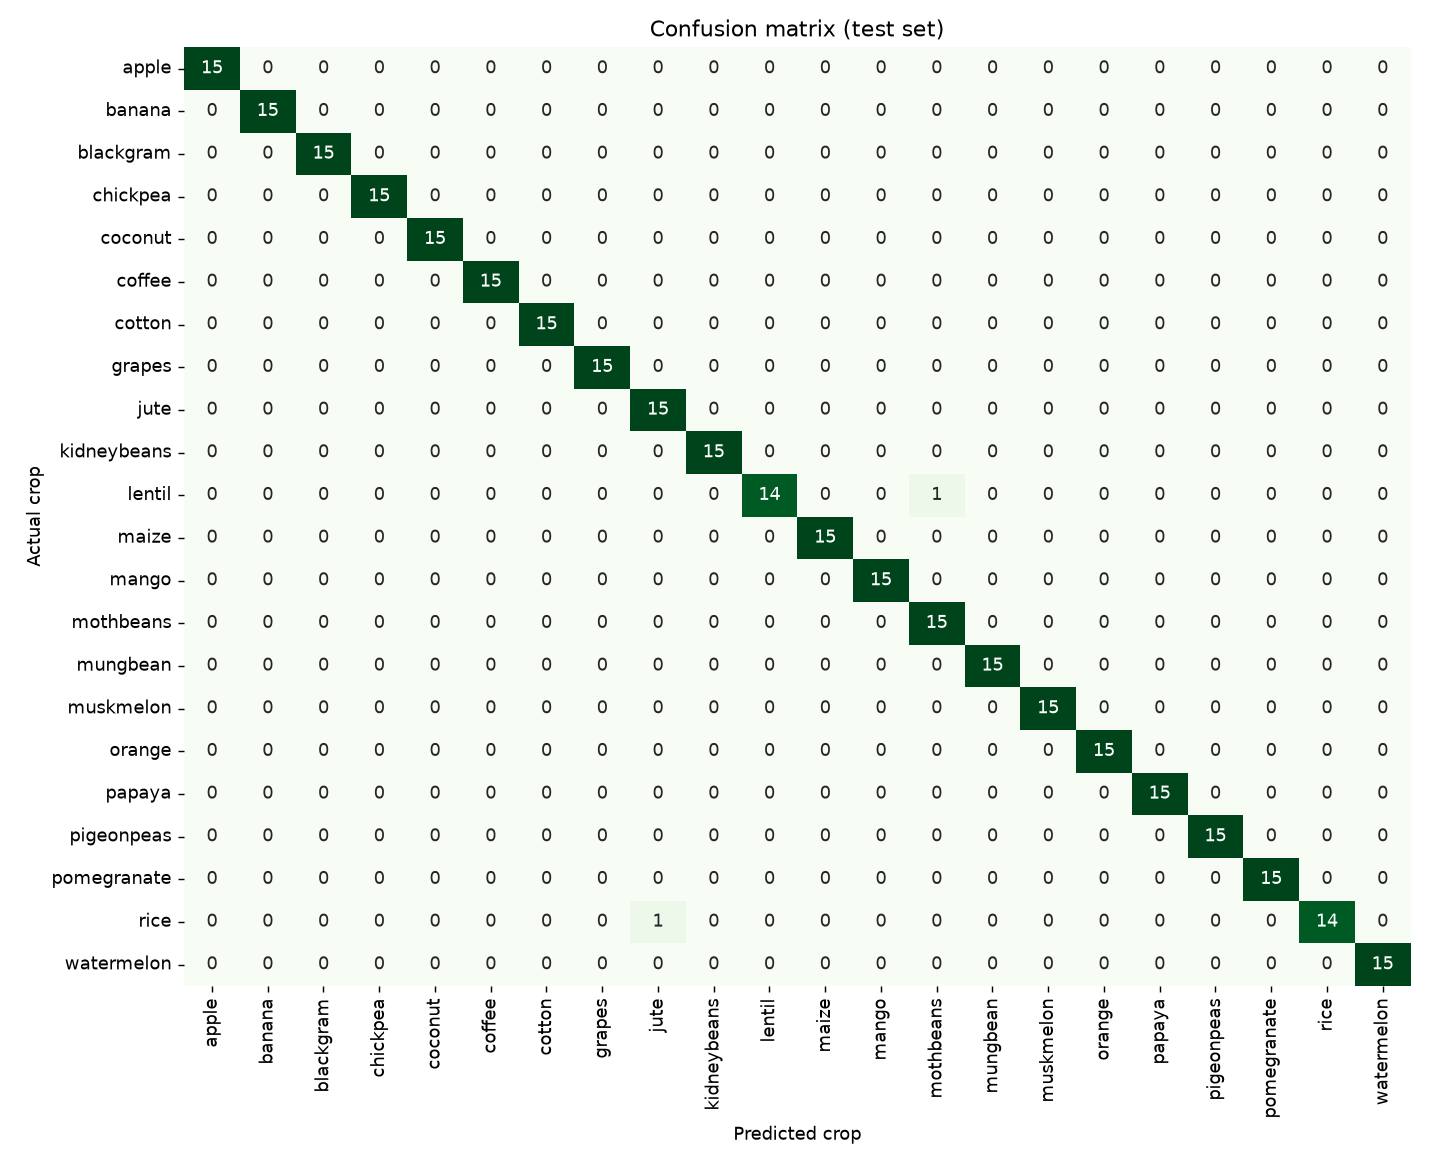

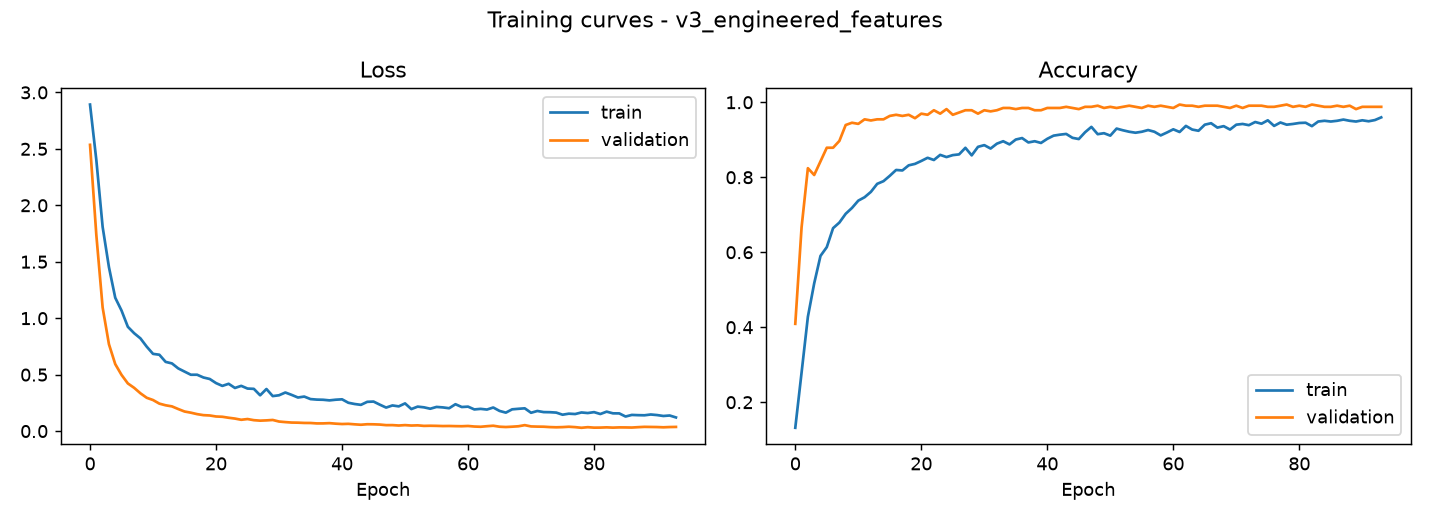

In [11]:
display(Image("results/confusion_matrix.png"))
display(Image("results/training_curves.png"))

In [12]:
# Automatic interpretation of the results
import re
rep = open("results/classification_report.txt").read().splitlines()
rows = []
for line in rep:
    parts = line.split()
    if len(parts) == 5 and parts[0] not in ("macro", "weighted") and parts[0] != "accuracy":
        try: rows.append((parts[0], float(parts[3])))
        except ValueError: pass
rows.sort(key=lambda r: r[1])
tm = m["test_metrics"]
print(f"The model recognises the correct crop for {tm['accuracy']:.1%} of unseen test samples "
      f"(macro F1 = {tm['f1_macro']:.3f}).")
print("Weakest crops by F1:", ", ".join(f"{n} ({f:.2f})" for n, f in rows[:3]))
tr = exp_df.set_index("experiment").loc[m["best_experiment"]]
gap = tr["train_accuracy"] - tr["val_accuracy"]
print(f"Train vs validation accuracy gap: {gap:+.3f} -> "
      + ("little over-fitting." if abs(gap) < 0.03 else "check for over-fitting."))

The model recognises the correct crop for 99.4% of unseen test samples (macro F1 = 0.994).
Weakest crops by F1: jute (0.97), lentil (0.97), mothbeans (0.97)
Train vs validation accuracy gap: -0.006 -> little over-fitting.


**How to read the evaluation results.**
- **Accuracy**: the share of unseen test samples correctly classified. Since the dataset is balanced across crop classes, accuracy is a good headline indicator.
- **Precision / recall / F1-score (macro)**: averaged across all 22 crops so each class contributes equally. This helps identify whether one crop is harder to distinguish than others.
- **Confusion matrix**: the diagonal shows correct predictions; off-diagonal cells show which crops are being confused, usually because they share similar growing conditions.
- **Training curves**: if validation loss and training loss remain close, the model generalises well instead of memorising the training data.

### Presentation-ready conclusion template
The model achieved strong predictive performance on the unseen test set, showing that the selected FNN architecture is effective for crop recommendation. The raw features already separate most crop classes well, and the final chosen model provides a good balance between accuracy and simplicity. The main confusion occurs between crops with similar soil and climate requirements, which is expected in agricultural classification tasks. Overall, the project demonstrates that a neural network can provide reliable crop recommendations while also warning users when inputs fall outside the training range.

*(Write your own final paragraph here after the model run in your own words.)*


## 8. Saving the model (reproducibility)

In [13]:
for f in sorted(os.listdir("models")):
    print(f"models/{f:22s} {os.path.getsize('models/' + f):>8,} bytes")
print()
print(json.dumps(meta["experiment"], indent=2))

models/crop_fnn.keras          191,428 bytes
models/label_encoder.joblib        696 bytes
models/model_meta.json           1,386 bytes
models/scaler.joblib             1,263 bytes

{
  "name": "v3_engineered_features",
  "use_engineered_features": true,
  "hidden_units": [
    128,
    64,
    32
  ],
  "dropout": 0.3,
  "learning_rate": 0.001
}


The trained network (`crop_fnn.keras`), the fitted `scaler.joblib`, the `label_encoder.joblib`, the chosen hyper-parameters and the seed (`model_meta.json`, `config.json`) are all saved, so anyone can reload and reproduce the results with `python train.py`.

## 9. Demonstration (Gradio web interface)

In [14]:
import app
top3, notes = app.predict_crop(90, 42, 43, 21, 82, 6.5, 203)   # N,P,K,temp,humidity,pH,rainfall
print(top3); print(notes)

{'jute': 0.5217914581298828, 'rice': 0.47810953855514526, 'coffee': 6.625490641454235e-05}
Recommended crop: jute (confidence 52.2%).
Low confidence - several crops fit these conditions.

Advisory tool only. It was trained on data from India, so results may not suit Rwandan soils and climate. Confirm with a local agronomist (e.g. RAB extension officer) before planting.


In [15]:
demo = app.build_ui()
demo.launch(inline=True)      # opens the interface inside the notebook (or use: python app.py)

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset1.csv


## 10. Responsible use

**Risk 1 - dataset bias / transfer.** The data comes from India. Rwandan soils, altitude and rainfall patterns differ, so recommendations may be wrong for local farmers. *Reduction:* the app warns when an input is outside the training range, shows the top-3 crops with confidence instead of a single answer, labels itself as advisory, and recommends confirming with an agronomist (e.g. RAB extension officer). Long term: retrain with local soil-test data.

**Risk 2 - over-trust and over-confidence.** Softmax probabilities can look certain even for unusual inputs. *Reduction:* low-confidence notices, out-of-range warnings, and a human decision-maker in the loop.

**Risk 3 - the data ignores things farmers care about** (market price, seed availability, water access, land size). *Reduction:* present the output as one input to a decision, not the decision.